In [1]:
%pylab inline
import gc
import fitsio
import treecorr
import numpy as np
import catutil

Populating the interactive namespace from numpy and matplotlib


# Cosmic shear measurement on mocks

## merge 6 observational fields

In [8]:
nzs    =   4
def mergeFields():
    # here I use the dnnz since the mock is based on dnnz
    pzname  =   'dnnz' #demp/mizuki/dnnz
    pzDir   =   'wrkDir/catalog/'
    fname   =   'mock_nres13_r003_rotmat12_shear_catalog.fits'
    # 4 bins
    dataG  =   [[],[],[],[]]
    for fieldname in catutil.field_names:
        # mock catalog (will copy v2 to GW and idark)
        catFname=  'wrkDir/g3Sim/catalog_mock/shape/%s/%s' %(fieldname,fname)
        data   =   fitsio.read(catFname)
        # avoid infinite |e|
        mask0  =   data['e1_mock']**2.+data['e2_mock']**2.<10.
        # selection using measured photo-z (not the true source photo-z)
        pzsname=   os.path.join(pzDir,'%s_%s_zmask.fits' %(fieldname,pzname))
        for iz in range(nzs):
            zmsk   =   fitsio.read(pzsname)['%s_mask_%sbin' %(pzname,iz)]&mask0
            # merge observational fields
            dataG[iz].append(data[zmsk])
        del data,zmsk
        gc.collect()
    dataG=[np.hstack(dataG[i]) for i in range(nzs)]
    print('number of galaxies in each bin:',len(dataG[0]),len(dataG[1]),len(dataG[2]),len(dataG[3]))
    return dataG

In [9]:
%%time
dataG=mergeFields()

number of galaxies in each bin: 1778855 8665772 9547780 7432666
CPU times: user 3.55 s, sys: 27.8 s, total: 31.3 s
Wall time: 31.4 s


## Measuring correlations

In [10]:
def measure_cs(dataG):
    out={}
    for i in range(nzs):
        catEi  =   treecorr.Catalog(g1=dataG[i]['e1_mock'],g2=-dataG[i]['e2_mock'],\
                                    ra=dataG[i]['ra_mock'],dec=dataG[i]['dec_mock'],\
                                    w=dataG[i]['weight'],ra_units='deg',dec_units='deg') 
        for j in range(i,nzs):
            catEj  =   treecorr.Catalog(g1=dataG[i]['e1_mock'],g2=-dataG[i]['e2_mock'],\
                                        ra=dataG[i]['ra_mock'],dec=dataG[i]['dec_mock'],\
                                        w=dataG[i]['weight'],ra_units='deg',dec_units='deg') 
            # correlation 
            cor.clear()
            cor.process(catEi,catEj)
            del catEj
            gc.collect()
            out.update({'%d%d'%(i,j):cor.copy()})
    return out
cor  =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')

In [11]:
%%time
cors=measure_cs(dataG)

CPU times: user 50min 40s, sys: 23.6 s, total: 51min 3s
Wall time: 3min 10s


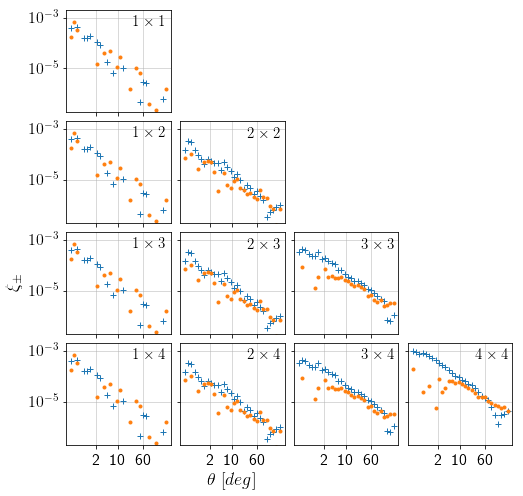

In [16]:
# make plot
plt.close()
fig = plt.figure(figsize=(8,8))
for i in range(nzs):
    for j in range(i,nzs):
        ax = plt.subplot2grid((8, 8), (j*2, i*2), colspan=2,rowspan=2)
        ax.set_ylim(2e-7,2e-3)
        ax.set_title(r'$%d \times %d$' %(i+1,j+1),fontsize=15,y=1.0, pad=-15,x=0.8)
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.grid()
        if i!=0:
            #ax.get_yaxis().set_visible(False)
            ax.set_yticklabels(('',''))
            #ax.set_yticklabels(('$10^{-5}$','$10^{-4}$'))
        if j!=nzs-1:
            #ax.get_xaxis().set_visible(False)
            ax.set_xticks((2,10,60))
            ax.set_xticklabels(('','',''))
        else:
            ax.set_xticks((2,10,60))
            ax.set_xticklabels(('2','10','60'))
        if i==0 and j==2:
            ax.set_ylabel(r'$\xi_{\pm}$')
        if j==nzs-1 and i==1:
            ax.set_xlabel(r'$\theta~[deg]$')
        ax.plot(cors['%d%d'%(i,j)].rnom,cors['%d%d'%(i,j)].xip,'+')
        ax.plot(cors['%d%d'%(i,j)].rnom,cors['%d%d'%(i,j)].xim,'.')

Text(0, 0.5, '$\\xi^{+}$')

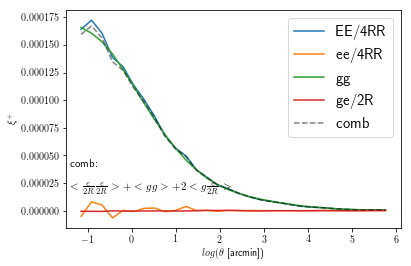

In [6]:
plt.close()
plt.plot(corE0.logr,corE1.xip/(2.*0.847)**2.,label='EE/4RR')
plt.plot(corE0.logr,corE0.xip/(2.*0.847)**2.,label='ee/4RR')
plt.plot(corE0.logr,corG.xip,label='gg')
plt.plot(corE0.logr,corGE0.xip/(2.*0.847),label='ge/2R')
plt.plot(corE0.logr,2*corGE0.xip/(2.*0.847)+corE0.xip/(2.*0.847)**2.+corG.xip,label='comb',color='black',ls='--',alpha=0.5)
plt.text(-1.4,1.5e-5,r'$<\frac{e}{2R} \frac{e}{2R}>+ <g g> + 2<g \frac{e}{2R}>$',fontsize=11)
plt.text(-1.4,4e-5,'comb:',fontsize=11)
plt.legend(fontsize=15)
plt.xlabel(r'$log (\theta$ [arcmin])')
plt.ylabel(r'$\xi^{+}$')

Text(0, 0.5, '$\\xi^{-}$')

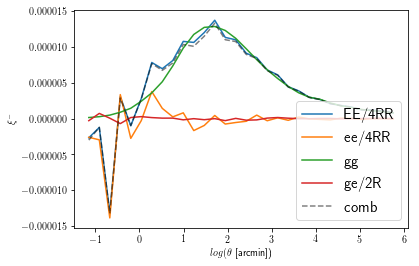

In [7]:
plt.close()
plt.plot(corE0.logr,corE1.xim/(2.*0.847)**2.,label='EE/4RR')
plt.plot(corE0.logr,corE0.xim/(2.*0.847)**2.,label='ee/4RR')
plt.plot(corE0.logr,corG.xim,label='gg')
plt.plot(corE0.logr,corGE0.xim/(2.*0.847),label='ge/2R')
plt.plot(corE0.logr,2*corGE0.xim/(2.*0.847)+corE0.xim/(2.*0.847)**2.+corG.xim,label='comb',color='black',ls='--',alpha=0.5)
plt.legend(fontsize=15,loc='lower right')
plt.xlabel(r'$log(\theta$ [arcmin])')
plt.ylabel(r'$\xi^{-}$')

In [32]:
isim=100;irot=10
fieldname='XMM'
fname   =   'mock_nres13_r%03d_rotmat%d_shear_catalog.fits' %(isim,irot)
catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/%s/%s' %(fieldname,fname)
data   =   fitsio.read(os.path.join(catFname))
# CS selection
# The following cut is to remove galaxies with infinite noise_mea
mask   =   data['e1_mock']**2.+data['e2_mock']**2.<100.
mask   =   mask&(data['z_source_mock']>0.3)
mask   =   mask&(data['z_source_mock']<1.5)
data   =   data[mask]
catG   =   treecorr.Catalog(g1=data['shear1_sim'],g2=-data['shear2_sim'],w=data['weight'],ra=data['ra_mock']\
                    ,dec=data['dec_mock'],ra_units='deg',dec_units='deg') 
# 
corG   =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corG.process(catG)

Text(0, 0.5, '$\\xi^{-}$')

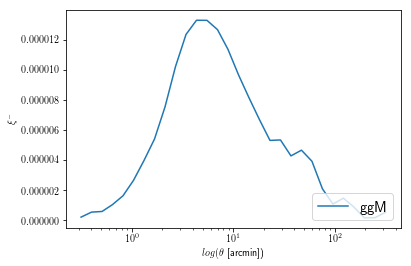

In [33]:
plt.close()
plt.plot(corE0.rnom,corG.xim,label='ggM')
plt.legend(fontsize=15,loc='lower right')
#plt.plot(corE0.rnom,corG.xip,label='ggP')
#plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$log(\theta$ [arcmin])')
plt.ylabel(r'$\xi^{-}$')

In [ ]:
corG.x

Text(0, 0.5, '$\\xi^{-}$')

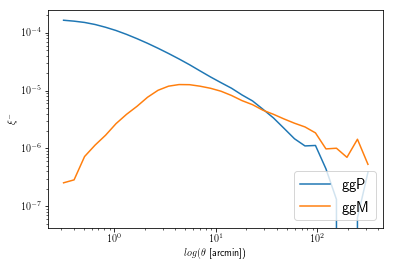

In [34]:
fieldname='WIDE12H'
catFname=   '/gpfs02/work/shirskms/HSCmock/S19A/shape/%s/%s' %(fieldname,fname)
data   =   fitsio.read(os.path.join(catFname))
# CS selection
# The following cut is to remove galaxies with infinite noise_mea
mask   =   data['e1_mock']**2.+data['e2_mock']**2.<100.
data   =   data[mask]
catG   =   treecorr.Catalog(g1=data['shear1_sim'],g2=-data['shear2_sim'],w=data['weight'],ra=data['ra_mock']\
                    ,dec=data['dec_mock'],ra_units='deg',dec_units='deg') 
# 
corG   =   treecorr.GGCorrelation(nbins=30,min_sep=0.281838293,max_sep=354.8133892,sep_units='arcmin')
corG.process(catG)
plt.close()
plt.plot(corE0.rnom,corG.xip,label='ggP')
plt.plot(corE0.rnom,corG.xim,label='ggM')
plt.legend(fontsize=15,loc='lower right')
plt.yscale('log')
plt.xscale('log')
plt.xlabel(r'$log(\theta$ [arcmin])')
plt.ylabel(r'$\xi^{-}$')

In [10]:
fieldname

'HECTOMAP'

In [154]:
for pend in ['G','E0','E1','GE0']:
    getAve(pend)

In [23]:
xipC_E1,ximC_E1,xicC_E1=getCor('E1')
xipC_E0,ximC_E0,xicC_E0=getCor('E0')
xipC_G,ximC_G,xicC_G=getCor('G')
xipC_GE0,ximC_GE0,xicC_GE0=getCor('GE0')

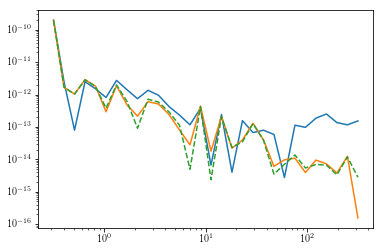

In [55]:
fname=os.path.join(datDir,'cor%s_ave.csv'%pend)
data=ascii.read(fname)
rnom=data['R_nom']
plt.plot(rnom,np.abs(ximC_E1[0]/(2.*0.847)**4.))
plt.plot(rnom,np.abs(ximC_E0[0]/(2.*0.847)**4.+ximC_G[0]+4.*ximC_GE0[0]/(2.*0.847)**2.))
plt.plot(rnom,np.abs(ximC_E0[0]/(2.*0.847)**4.),'--')
plt.xscale('log')
plt.yscale('log')

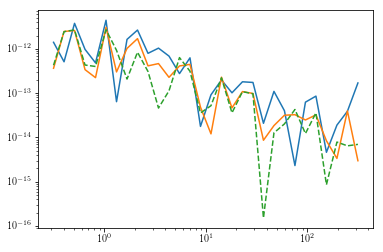

In [57]:
fname=os.path.join(datDir,'cor%s_ave.csv'%pend)
data=ascii.read(fname)
rnom=data['R_nom']
plt.plot(rnom,np.abs(xicC_E1[0]/(2.*0.847)**4.))
plt.plot(rnom,np.abs(xicC_E0[0]/(2.*0.847)**4.+xicC_G[0]+4.*xicC_GE0[0]/(2.*0.847)**2.))
plt.plot(rnom,np.abs(xicC_E0[0]/(2.*0.847)**4.),'--')
plt.xscale('log')
plt.yscale('log')

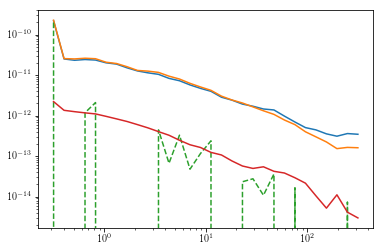

In [56]:
fname=os.path.join(datDir,'cor%s_ave.csv'%pend)
data=ascii.read(fname)
rnom=data['R_nom']
plt.plot(rnom,(xipC_E1[0]/(2.*0.847)**4.))
plt.plot(rnom,(xipC_E0[0]/(2.*0.847)**4.+xipC_G[0]+4.*xipC_GE0[0]/(2.*0.847)**2.))
plt.plot(rnom,(xipC_E0[0]/(2.*0.847)**4.),'--')
plt.plot(rnom,4.*xipC_GE0[0]/(2.*0.847)**2.)
plt.xscale('log')
plt.yscale('log')

In [29]:
xipC_GE0[0]

array([1.59376972e-12, 9.70816532e-13, 8.98977652e-13, 8.39585376e-13,
       7.90845838e-13, 6.89335589e-13, 5.96792220e-13, 5.14533706e-13,
       4.30033303e-13, 3.57353752e-13, 2.88968991e-13, 2.35301564e-13,
       1.76882077e-13, 1.37050181e-13, 1.17284993e-13, 8.87902842e-14,
       7.66433531e-14, 5.45551236e-14, 4.09231375e-14, 3.56760031e-14,
       3.91359217e-14, 3.02824756e-14, 2.74789391e-14, 2.09937781e-14,
       1.54332362e-14, 7.51500574e-15, 3.73068311e-15, 7.96438554e-15,
       2.96561063e-15, 2.14058471e-15])

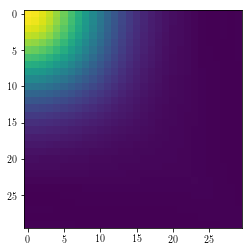

In [150]:
plt.imshow(xip_cov)

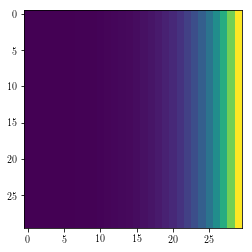

In [149]:
data=ascii.read(fname)
Xgrid,Ygrid=np.meshgrid(data['R_nom'].data,data['R_nom'].data)
plt.imshow(Xgrid)

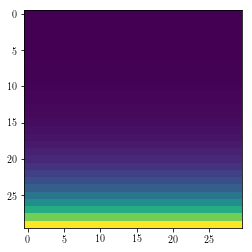

In [143]:
plt.imshow(Ygrid)

In [151]:
xx=np.ravel(Xgrid)
yy=np.ravel(Ygrid)
pp=np.ravel(xip_cov)
mm=np.ravel(xim_cov)

In [102]:
c=b.T.dot(b)

In [97]:
np.cov([1,2],[2,3],rowvar=0)

array([[0.5, 0.5],
       [0.5, 0.5]])

In [134]:
data['R_nom'].data

array([  0.31744,   0.40272,   0.5109 ,   0.64814,   0.82224,   1.0431 ,
         1.3233 ,   1.6788 ,   2.1298 ,   2.7019 ,   3.4277 ,   4.3484 ,
         5.5165 ,   6.9984 ,   8.8784 ,  11.263  ,  14.289  ,  18.127  ,
        22.997  ,  29.174  ,  37.011  ,  46.953  ,  59.566  ,  75.567  ,
        95.866  , 121.62   , 154.29   , 195.73   , 248.31   , 315.02   ])

In [82]:
b=b.reshape(30,1)

In [71]:
np.dot(b,b.T)

1.4599448690924502e-07

In [59]:
a=data['xip']

In [61]:
a.data

array([ 1.6110e-04,  1.5595e-04,  1.4839e-04,  1.3746e-04,  1.2362e-04,
        1.0905e-04,  9.3770e-05,  7.9184e-05,  6.5839e-05,  5.3970e-05,
        4.3705e-05,  3.5078e-05,  2.7934e-05,  2.2153e-05,  1.7754e-05,
        1.4366e-05,  1.1709e-05,  9.6185e-06,  7.9104e-06,  6.4504e-06,
        5.0781e-06,  3.8442e-06,  2.8579e-06,  1.9824e-06,  1.1754e-06,
        6.2023e-07,  4.0602e-07,  1.4700e-07, -2.8016e-07, -1.8681e-07])

In [50]:
data['xip'].data.T.shape

(30,)

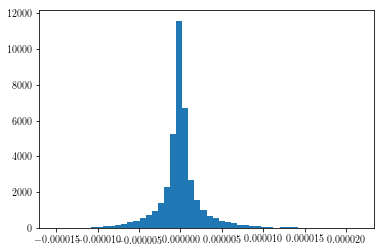

In [35]:
pend='G' #G,E0,E1,GE0
getPlotHist(pend)

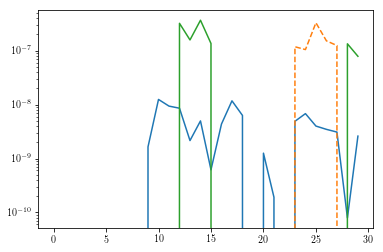

In [93]:
irot=10;isim=45
fname=os.path.join(datDir,'sim-%03d' %isim,'rotmat%d_cor%s.csv' %(irot,pend))
data=ascii.read(fname)
plt.close()
plt.plot(xip_ave)
plt.plot(data['xip'],ls='--')
plt.plot(corGE0.xip,label='gg')
plt.yscale('log')

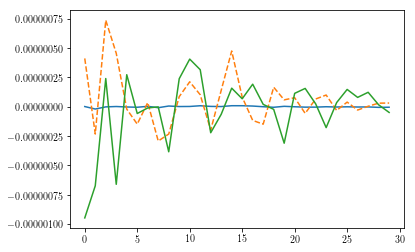

In [94]:
plt.close()
plt.plot(xim_ave)
plt.plot(data['xim'],ls='--')
plt.plot(corGE0.xim,label='gg')

In [ ]:
def plotCS(err_type='total', log_plot=True, theta_p=4.0, theta_m=40.0):
    """
    Routine to make a figure showing the cosmic shear signals and errors.
    """
    # Get the signal plus cosmic variance errors.
    thetap, xip, xip_var, thetam, xim, xim_var = load_CS(0.0, 0.0, unravel=1)

    # Make the plot.
    fig = plt.figure()
    if log_plot:
        plt.plot(thetap, xip, color='red', label=r'$\xi_+$')
        plt.plot(thetam, xim, color='blue', label=r'$\xi_-$')
        if err_type == 'total':
            plt.errorbar(thetap, xip, np.sqrt(xip_var), color='red')
            plt.errorbar(thetam, xim, np.sqrt(xim_var), color='blue')
        elif err_type == 'sn':
            raise RuntimeError("Error type not implemented: %s"%err_type)
            plt.errorbar(thetap, xip, np.sqrt(sn_var), color='red')
            plt.errorbar(thetam, xim, np.sqrt(sn_var), color='blue')
        else:
            raise RuntimeError("Unknown error type: %s"%err_type)

        plt.ylabel(r'$\xi_+$ or $\xi_-$')
        plt.yscale('log')
    else:
        plt.plot(thetap, 1e5*thetap*xip, color='red', label=r'$\theta\xi_+$')
        plt.plot(thetam, 1e5*thetam*xim, color='blue', label=r'$\theta\xi_-$')
        if err_type == 'total':
            plt.errorbar(thetap, 1e5*thetap*xip, 1e5*thetap*np.sqrt(xip_var), color='red')
            plt.errorbar(thetam, 1e5*thetam*xim, 1e5*thetam*np.sqrt(xim_var), color='blue')
        elif err_type == 'sn':
            raise RuntimeError("Error type not implemented: %s"%err_type)
            plt.errorbar(thetap, 1e5*thetap*xip, 1e5*thetap*np.sqrt(sn_var), color='red')
            plt.errorbar(thetam, 1e5*thetam*xim, 1e5*thetam*np.sqrt(sn_var), color='blue')
        else:
            raise RuntimeError("Unknown error type: %s"%err_type)
        plt.ylabel(r'$10^5\theta\xi_+$ or $10^5\theta\xi_-$')

    plt.axvline(theta_p/60.0, linestyle="dashed", color='red')
    plt.axvline(theta_m/60.0, linestyle="dashed", color='blue')
    plt.xlabel(r'$\theta$ [degrees]')
    plt.xscale('log')
    plt.legend()
    return fig

def plot_additive_req_general(outfile=None, theta_p=4.0, theta_m=40.0):
    """
    Routine to make a general plot for requirements on additive errors using
    the first year survey area.
    Based on Sec 3.3.3, Eq. 20
    <cc> = xi_+/SN_CS+
    """

    thetap, xip, xip_var, thetam, xim, xim_var = load_CS(0.0, 0.0, unravel=1)
    SN = getCS_SN(theta_p, theta_m, "p")

    fig = plt.figure()
    plt.plot(thetap, xip/SN, 'b', label=r'$\frac{\xi_+}{%.1f}$' % (SN))
    plt.xlabel(r'$\theta$ [degrees]')
    plt.ylabel(r'Requirement on $\langle cc \rangle$')
    plt.xscale('log')
    plt.yscale('log')

    plt.axvline(theta_p/60.0, linestyle="dashed", color='red')

    dat = np.column_stack([thetap, xip/SN])
    if outfile is not None:
        np.savetxt(outfile, dat, header="Col 1: Theta (degrees) \n Col 2: xip/SN ")

    return fig

def plot_additive_req(fname, theta_p=4.0, theta_m=40.0, stat_factor=0.5, outfile=None):
    """
    Routine to make a plot for requirements on additive errors using the first
    year survey area.
    The user needs to input a filename which contains the shape correlation of stars.
    Based on Sec 3.3.3, Eq. 22
    delta a^2 = stat_factor xi_+/SN_CS+/<estar estar>
    """
    tht, estarxip_all = np.loadtxt(fname, usecols=(0, 1), unpack=1, skiprows=1)

    thetap, xip, xip_var, thetam, xim, xim_var = load_CS(0.0, 0.0, unravel=1)
    SN = getCS_SN(theta_p, theta_m, "p")

    from scipy.interpolate import interp1d
    xip_spl = interp1d(np.log(thetap), np.log(xip), kind="cubic")

    fig = plt.figure()
    plt.plot(tht, stat_factor/SN/estarxip_all*np.exp(xip_spl(np.log(tht))), 'bo', label=r'$\frac{%.1f}{%.1f} \frac{\xi_+}{\langle e_* e_* \rangle}$' % (stat_factor, SN))
    plt.axvline(theta_p/60.0, linestyle="dashed", color='red')
    plt.xlabel(r'$\theta$ [degrees]')
    plt.ylabel(r'Requirement on $\delta (a^2)$')
    plt.xscale('log')
    plt.yscale('log')

    if outfile is not None:
        dat = np.column_stack([tht,stat_factor/SN/estarxip_all*np.exp(xip_spl(np.log(tht)))])
        np.savetxt(outfile, dat, header="Col 1: Theta (degrees) \n Col 2: da2 requirement ")

    return fig

def load_CS(min_p_theta, min_m_theta, unravel=0, retcov=0):

    # Divide all errors and measurements by 4*R**2 where R=0.812, since
    # covariances did not take into account Responsivity in the cosmic shear
    # estimator.  Note this is different from the true Resp in the data, as the
    # mock is constructed by randomly rotating observed ellipticities.
    mockResp = 0.812

    # Read the various files from Masato
    cov_m = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_m.cov",
            usecols=([0, 1, 2]), names=(["ti", "tj", "covar"]), delim_whitespace=1, header=None)
    cov_m_ti = cov_m.ti.values
    cov_m_tj = cov_m.tj.values
    cov_m = cov_m.covar.values/(4.*mockResp**2)**2


    cov_p = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_p.cov",
            usecols=([0, 1, 2]), names=(["ti", "tj", "covar"]), delim_whitespace=1, header=None)
    cov_p_ti = cov_p.ti.values
    cov_p_tj = cov_p.tj.values
    cov_p = cov_p.covar.values/(4.*mockResp**2)**2

    cov_x = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_pm.cross_cov",
            usecols=([0, 1, 2]), names=(["ti", "tj", "covar"]), delim_whitespace=1, header=None)
    cov_x_ti = cov_x.ti.values
    cov_x_tj = cov_x.tj.values
    cov_x = cov_x.covar.values/(4.*mockResp**2)**2

    # Ok now we have to subsample based on theta values
    xi_m = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_m.mean_sqrtvar",
            names=(["ti", "xi", "xi_err"]), header=None, delim_whitespace=1)
    xi_m.xi /= (4.*mockResp**2)
    xi_m.xi_err /= (4.*mockResp**2)

    xi_p = pandas.read_csv("HSCS16A_combinedarea_1000rea_full_xi_p.mean_sqrtvar",
            names=(["ti", "xi", "xi_err"]), header=None, delim_whitespace=1)

    xi_p.xi /= (4.*mockResp**2)
    xi_p.xi_err /= (4.*mockResp**2)

    # Prune theta values
    idx = (cov_m_ti>min_m_theta) & (cov_m_tj>min_m_theta)
    cov_m = cov_m[idx]
    msize = np.sum(xi_m.ti.values>min_m_theta)
    cov_m = cov_m.reshape((msize, msize))

    idx = (cov_p_ti>min_p_theta) & (cov_p_tj>min_p_theta)
    cov_p = cov_p[idx]
    psize = np.sum(xi_p.ti.values>min_p_theta)
    cov_p = cov_p.reshape((psize, psize))

    idx = (cov_x_ti>min_p_theta) & (cov_x_tj>min_m_theta)
    cov_x = cov_x[idx]
    cov_x = cov_x.reshape((psize, msize))

    # Now write the full covariance matrix with the pruned vectors
    fullcov = np.zeros((msize+psize)*(msize+psize)).reshape((msize+psize,
        msize+psize))

    for i in xrange(msize+psize):
        for j in xrange(i, msize+psize):
            if i<psize and j<psize:
                fullcov[i][j] = cov_p[i][j]
            elif i<psize and j>=psize:
                fullcov[i][j] = cov_x[i][j-psize]
            elif i>=psize and j<psize:
                fullcov[i][j] = cov_x[i-psize][j]
            elif i>=psize and j>=psize:
                fullcov[i][j] = cov_m[i-psize][j-psize]
            fullcov[j][i] = fullcov[i][j]

    idx_m = xi_m.ti.values>min_m_theta
    idx_p = xi_p.ti.values>min_p_theta

    xi_p_xi_m_arr = np.append(xi_p.xi.values[idx_p], xi_m.xi.values[idx_m])
    theta_arr = np.append(xi_p.ti.values[idx_p], xi_m.ti.values[idx_m])

    if unravel:
        if not retcov:
            return xi_p.ti.values[idx_p]/60., xi_p.xi.values[idx_p], np.diag(fullcov)[:psize], xi_m.ti.values[idx_m]/60., xi_m.xi.values[idx_m], np.diag(fullcov)[psize:]
        else:
            return xi_p.ti.values[idx_p]/60., xi_p.xi.values[idx_p], fullcov[:psize, :psize], xi_m.ti.values[idx_m]/60., xi_m.xi.values[idx_m], fullcov[psize:, psize:]

    else:
        return theta_arr/60., xi_p_xi_m_arr, fullcov

def getCS_SN(theta_p=4.0, theta_m=40.0, which="a"):
    """
    Routine to read in file with signal and errors for the cosmic shear, assumes the
    first year area
    The covariances include shape noise errors as well
    """
    if which == "a":
        tht, xivec, covar = load_CS(theta_p, theta_m)
        SN = (np.transpose(xivec).dot(inv(covar).dot(xivec)))**0.5
    else:
        thetap, xip, xip_var, thetam, xim, xim_var = load_CS(theta_p, theta_m, unravel=1, retcov=1)
        if which == "m":
            SN = (np.transpose(xim).dot(inv(xim_var).dot(xim)))**0.5
        elif which == "p":
            SN = (np.transpose(xip).dot(inv(xip_var).dot(xip)))**0.5


    print ("Cosmic shear SN: %.2f" % SN)
    return SN